# Similarity & Clustering Implementation

We will analyze a set of news headlines to understand how text similarity and clustering work in NLP. Using TF-IDF & word embeddings, cosine similarity, and K-Means clustering, we group similar headlines and visualize them using PCA. This helps us learn how search engines and recommendation systems organize related text.

## Load Data

This cell loads the JSON dataset "News_Category_Dataset_v2.json" into a pandas DataFrame and displays the first 10 rows to inspect its structure and content.

In [ ]:
import os

# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import pandas as pd

drive_path = '/content/drive/My Drive/Deep Learning Content/NLP/NLP Colab Notebooks/Datasets/Similarity & clustering/News_Category_Dataset_v2.json'
df = pd.read_json(drive_path, lines=True)
df.head(10)

,category,headline,authors,link,short_description,date
0,CRIME,There Were 2 Mass Shootings In Texas Last Week...,Melissa Jeltsen,https://www.huffingtonpost.com/entry/texas-ama...,She left her husband. He killed their children...,2018-05-26
1,ENTERTAINMENT,Will Smith Joins Diplo And Nicky Jam For The 2...,Andy McDonald,https://www.huffingtonpost.com/entry/will-smit...,Of course it has a song.,2018-05-26
2,ENTERTAINMENT,Hugh Grant Marries For The First Time At Age 57,Ron Dicker,https://www.huffingtonpost.com/entry/hugh-gran...,The actor and his longtime girlfriend Anna Ebe...,2018-05-26
3,ENTERTAINMENT,Jim Carrey Blasts 'Castrato' Adam Schiff And D...,Ron Dicker,https://www.huffingtonpost.com/entry/jim-carre...,The actor gives Dems an ass-kicking for not fi...,2018-05-26
4,ENTERTAINMENT,Julianna Margulies Uses Donald Trump Poop Bags...,Ron Dicker,https://www.huffingtonpost.com/entry/julianna-...,"The ""Dietland"" actress said using the bags is ...",2018-05-26
5,ENTERTAINMENT,Morgan Freeman 'Devastated' That Sexual Harass...,Ron Dicker,https://www.huffingtonpost.com/entry/morgan-fr...,"""It is not right to equate horrific incidents ...",2018-05-26
6,ENTERTAINMENT,Donald Trump Is Lovin' New McDonald's Jingle I...,Ron Dicker,https://www.huffingtonpost.com/entry/donald-tr...,"It's catchy, all right.",2018-05-26
7,ENTERTAINMENT,What To Watch On Amazon Prime That’s New This ...,Todd Van Luling,https://www.huffingtonpost.com/entry/amazon-pr...,There's a great mini-series joining this week.,2018-05-26
8,ENTERTAINMENT,Mike Myers Reveals He'd 'Like To' Do A Fourth ...,Andy McDonald,https://www.huffingtonpost.com/entry/mike-myer...,"Myer's kids may be pushing for a new ""Powers"" ...",2018-05-26
9,ENTERTAINMENT,What To Watch On Hulu That’s New This Week,Todd Van Luling,https://www.huffingtonpost.com/entry/hulu-what...,You're getting a recent Academy Award-winning ...,2018-05-26


In [ ]:
df.tail()

,category,headline,authors,link,short_description,date
200848,TECH,RIM CEO Thorsten Heins' 'Significant' Plans Fo...,"Reuters, Reuters",https://www.huffingtonpost.com/entry/rim-ceo-t...,Verizon Wireless and AT&T are already promotin...,2012-01-28
200849,SPORTS,Maria Sharapova Stunned By Victoria Azarenka I...,,https://www.huffingtonpost.com/entry/maria-sha...,"Afterward, Azarenka, more effusive with the pr...",2012-01-28
200850,SPORTS,"Giants Over Patriots, Jets Over Colts Among M...",,https://www.huffingtonpost.com/entry/super-bow...,"Leading up to Super Bowl XLVI, the most talked...",2012-01-28
200851,SPORTS,Aldon Smith Arrested: 49ers Linebacker Busted ...,,https://www.huffingtonpost.com/entry/aldon-smi...,CORRECTION: An earlier version of this story i...,2012-01-28
200852,SPORTS,Dwight Howard Rips Teammates After Magic Loss ...,,https://www.huffingtonpost.com/entry/dwight-ho...,The five-time all-star center tore into his te...,2012-01-28


In [ ]:
df = df[['headline']].dropna()
df.head()

,headline
0,There Were 2 Mass Shootings In Texas Last Week...
1,Will Smith Joins Diplo And Nicky Jam For The 2...
2,Hugh Grant Marries For The First Time At Age 57
3,Jim Carrey Blasts 'Castrato' Adam Schiff And D...
4,Julianna Margulies Uses Donald Trump Poop Bags...


In [ ]:
import re
import nltk
nltk.download('stopwords')
from nltk.corpus import stopwords

stop_words = set(stopwords.words("english"))

def clean_text(text):
    # Lowercase
    text = text.lower()

    # Remove punctuation & special characters
    text = re.sub(r'[^a-zA-Z0-9\s]', '', text)


   # Remove extra spaces
    text = re.sub(r'\s+', ' ', text).strip()

    return text

# Apply cleaning
df['clean_headline'] = df['headline'].apply(clean_text)

# For Word2Vec — tokenize + remove stopwords
df['tokens'] = df['clean_headline'].apply(lambda x:
                                          [w for w in x.split() if w not in stop_words])
df.head(10)


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


,headline,clean_headline,tokens
0,There Were 2 Mass Shootings In Texas Last Week...,there were 2 mass shootings in texas last week...,"[2, mass, shootings, texas, last, week, 1, tv]"
1,Will Smith Joins Diplo And Nicky Jam For The 2...,will smith joins diplo and nicky jam for the 2...,"[smith, joins, diplo, nicky, jam, 2018, world,..."
2,Hugh Grant Marries For The First Time At Age 57,hugh grant marries for the first time at age 57,"[hugh, grant, marries, first, time, age, 57]"
3,Jim Carrey Blasts 'Castrato' Adam Schiff And D...,jim carrey blasts castrato adam schiff and dem...,"[jim, carrey, blasts, castrato, adam, schiff, ..."
4,Julianna Margulies Uses Donald Trump Poop Bags...,julianna margulies uses donald trump poop bags...,"[julianna, margulies, uses, donald, trump, poo..."
5,Morgan Freeman 'Devastated' That Sexual Harass...,morgan freeman devastated that sexual harassme...,"[morgan, freeman, devastated, sexual, harassme..."
6,Donald Trump Is Lovin' New McDonald's Jingle I...,donald trump is lovin new mcdonalds jingle in ...,"[donald, trump, lovin, new, mcdonalds, jingle,..."
7,What To Watch On Amazon Prime That’s New This ...,what to watch on amazon prime thats new this week,"[watch, amazon, prime, thats, new, week]"
8,Mike Myers Reveals He'd 'Like To' Do A Fourth ...,mike myers reveals hed like to do a fourth aus...,"[mike, myers, reveals, hed, like, fourth, aust..."
9,What To Watch On Hulu That’s New This Week,what to watch on hulu thats new this week,"[watch, hulu, thats, new, week]"


## Feature Extraction using TF-IDF

This cell initializes a `TfidfVectorizer` to convert the `headline` text data into a matrix of TF-IDF features. It removes common English stop words and limits the number of features to 10,000. The `fit_transform` method then applies this to the 'headline' column, and the resulting shape of the feature matrix `X` is printed.

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(stop_words='english', max_features=10000)
X_tfidf = tfidf.fit_transform(df['clean_headline'])

X_tfidf.shape


(200853, 10000)

## Cosine Similarity Demonstration

This cell demonstrates the concept of cosine similarity. It selects a sample headline vector (the 10th headline in this case) and calculates its cosine similarity with the first 10 headlines in the dataset. The original sample headline and the resulting similarity scores are then printed.

In [ ]:
from sklearn.metrics.pairwise import cosine_similarity

sample_vec = X_tfidf[9]
similarities = cosine_similarity(sample_vec, X_tfidf[:10])

print(df['headline'][9])
print(similarities)

What To Watch On Hulu That’s New This Week
[[0.1227533  0.         0.         0.05317594 0.         0.
  0.06926176 0.53770178 0.         1.        ]]


The similarity score between sentence 9 and sentence 7 was relatively higher(0.408..)due to the presence of the common phrase 'What To Watch On' in both.

## K-Means Clustering

This cell applies the K-Means clustering algorithm to the TF-IDF vectorized headlines. It initializes K-Means with 10 clusters (`k=10`) and a fixed `random_state` for reproducibility. The `fit_predict` method assigns each headline to a cluster, and these cluster labels are then added as a new column `cluster` to the original DataFrame `df`.

In [ ]:
from sklearn.cluster import KMeans

k = 10
kmeans = KMeans(n_clusters=k, random_state=42)
labels = kmeans.fit_predict(X_tfidf)

df['cluster'] = labels
df.head(10)

,headline,clean_headline,tokens,cluster
0,There Were 2 Mass Shootings In Texas Last Week...,there were 2 mass shootings in texas last week...,"[2, mass, shootings, texas, last, week, 1, tv]",9
1,Will Smith Joins Diplo And Nicky Jam For The 2...,will smith joins diplo and nicky jam for the 2...,"[smith, joins, diplo, nicky, jam, 2018, world,...",3
2,Hugh Grant Marries For The First Time At Age 57,hugh grant marries for the first time at age 57,"[hugh, grant, marries, first, time, age, 57]",9
3,Jim Carrey Blasts 'Castrato' Adam Schiff And D...,jim carrey blasts castrato adam schiff and dem...,"[jim, carrey, blasts, castrato, adam, schiff, ...",9
4,Julianna Margulies Uses Donald Trump Poop Bags...,julianna margulies uses donald trump poop bags...,"[julianna, margulies, uses, donald, trump, poo...",4
5,Morgan Freeman 'Devastated' That Sexual Harass...,morgan freeman devastated that sexual harassme...,"[morgan, freeman, devastated, sexual, harassme...",9
6,Donald Trump Is Lovin' New McDonald's Jingle I...,donald trump is lovin new mcdonalds jingle in ...,"[donald, trump, lovin, new, mcdonalds, jingle,...",4
7,What To Watch On Amazon Prime That’s New This ...,what to watch on amazon prime thats new this week,"[watch, amazon, prime, thats, new, week]",9
8,Mike Myers Reveals He'd 'Like To' Do A Fourth ...,mike myers reveals hed like to do a fourth aus...,"[mike, myers, reveals, hed, like, fourth, aust...",9
9,What To Watch On Hulu That’s New This Week,what to watch on hulu thats new this week,"[watch, hulu, thats, new, week]",9


## Inspecting Cluster Contents



In [ ]:
for c in range(k):
    print(f"\nCluster {c}")
    print(df[df['cluster'] == c]['headline'].head(5).tolist())


Cluster 0
['The Supreme Court Just Made It A Lot Harder For You To Sue Your Employer', 'Gun Owners And Non-Gun Owners Actually Agree On A Lot Of Gun Reforms', "Sinclair Journalists Worry They’re Being Watched: 'There's A Lot Held Over Us'", "The Agencies Key To Trump's Immigration Agenda Keep A Lot Of Secrets", 'People Sent A Lot Of Racist Email To UCLA After 3 Athletes Were Arrested In China']

Cluster 1
['Kate & William PDA Alert! Duchess Kisses Husband, Plays With Puppy Lupo At Audi Polo Match (PHOTOS, VIDEO)']

Cluster 2
["Break Out The Book Of Shadows, The 'Charmed' Reboot Trailer Is Here", 'Ariana Grande And Mac Miller Reportedly Break Up', 'Trump To Announce Whether U.S. Will Break The Iran Nuclear Deal', 'A Third Woman Is Suing To Break A Trump-Related Nondisclosure Agreement', 'Ex-Playboy Model Who Claims Affair With Trump Sues To Break Silence']

Cluster 3
["Will Smith Joins Diplo And Nicky Jam For The 2018 World Cup's Official Song", 'Dave Grohl Wants To Apologize To The Wo

This prints a sample of headlines from each cluster so we can inspect what kind of news items the model grouped together. It helps us verify whether K-Means formed meaningful and coherent clusters

## Visualizing Clusters with PCA

The Principal Component Analysis (PCA) is used to reduce the high-dimensional TF-IDF vectors to 2 dimensions. This is done for a subset of the data to ensure efficient visualization. A scatter plot is then generated to visualize the clusters in this 2D space, with different colors representing different clusters. This helps in understanding the separation and distribution of the clusters.

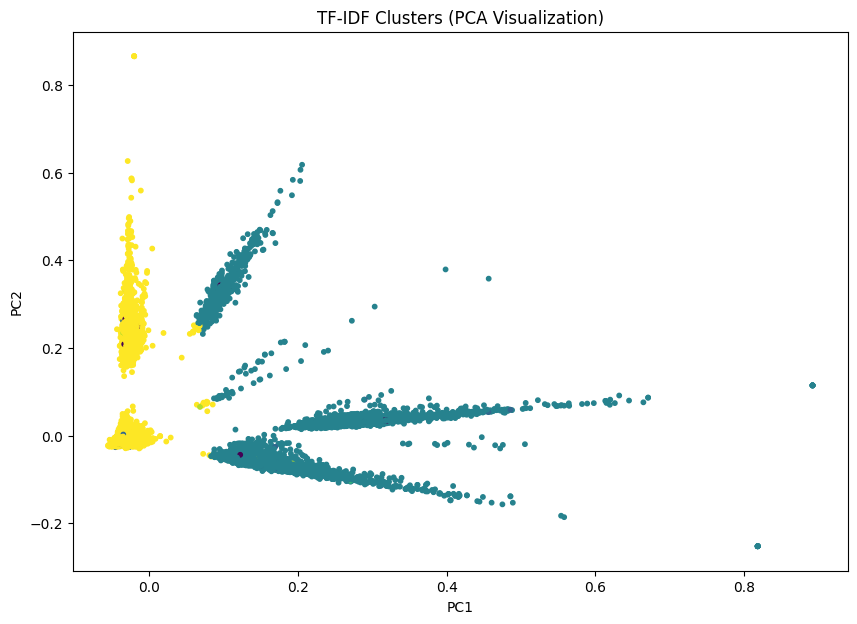

In [ ]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

#  TF-IDF sample for PCA
N = 50000
X_dense = X_tfidf[:N].toarray()
labels_small = labels[:N]

#  PCA
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_dense)

#  Plot
plt.figure(figsize=(10,7))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=labels_small, s=10)
plt.title("TF-IDF Clusters (PCA Visualization)")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.show()


The TF-IDF clusters appear more stretched and directional, forming elongated shapes in PCA space. This happens because TF-IDF relies on sparse keyword counts, which makes clusters more separated when documents share strong lexical similarity. The overlap between groups shows that TF-IDF struggles to capture deeper semantic meaning.

## Word2Vec Embeddings + Clustering

In [ ]:
!pip install gensim

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.9/27.9 MB 73.9 MB/s eta 0:00:00


In [ ]:
from gensim.models import Word2Vec

model = Word2Vec(
    sentences=df['tokens'],
    vector_size=100,
    window=5,
    min_count=2,
    workers=4,
    sg=1
)

# Build document embeddings by averaging word vectors
import numpy as np

def get_vector(tokens):
    vectors = [model.wv[w] for w in tokens if w in model.wv]
    return np.mean(vectors, axis=0) if vectors else np.zeros(100)

df['embedding'] = df['tokens'].apply(get_vector)
X_w2v = np.vstack(df['embedding'].values)

print("Word2Vec Embeddings Shape:", X_w2v.shape)


Word2Vec Embeddings Shape: (200853, 100)


In [ ]:
from sklearn.cluster import KMeans

k = 10
kmeans_w2v = KMeans(n_clusters=k, random_state=42)
df['cluster_w2v'] = kmeans_w2v.fit_predict(X_w2v)

print(df['cluster_w2v'].value_counts())


cluster_w2v
6    32112
5    27593
8    26621
3    26247
7    19896
9    15701
4    15349
2    14792
1    12627
0     9915
Name: count, dtype: int64


In [ ]:
for c in range(k):
    print(f"\n--- Cluster {c} ---")
    print(df[df['cluster_w2v'] == c]['headline'].head(5).tolist())



--- Cluster 0 ---
['What To Watch On Amazon Prime That’s New This Week', 'What To Watch On Hulu That’s New This Week', 'The 20 Funniest Tweets From Women This Week', "'Late Night' Writer's Breathless Royal Wedding Recap Is The Only One You Need", '14 Trips To Take From New York City On A Long Weekend']

--- Cluster 1 ---
["Kanye West Spent $85,000 On Photo Of Whitney Houston's Bathroom For Album Cover", "Kim Kardashian Wished Kanye West A Happy Anniversary And, Fine, It's Pretty Cute", 'Anna Kournikova Dancing With Her Bouncing Baby Is The Cutest Thing', 'The Latest Entries From The Comedy Wildlife Photo Awards Will Cheer You Up', 'Chrissy Teigen, John Legend Announce Name Of Baby Boy With Adorable Photo']

--- Cluster 2 ---
['There Were 2 Mass Shootings In Texas Last Week, But Only 1 On TV', 'Justin Timberlake Visits Texas School Shooting Victims', "Mystery 'Wolf-Like' Animal Reportedly Shot In Montana, Baffles Wildlife Officials", '2 Men Detonate Bomb Inside Indian Restaurant Near T

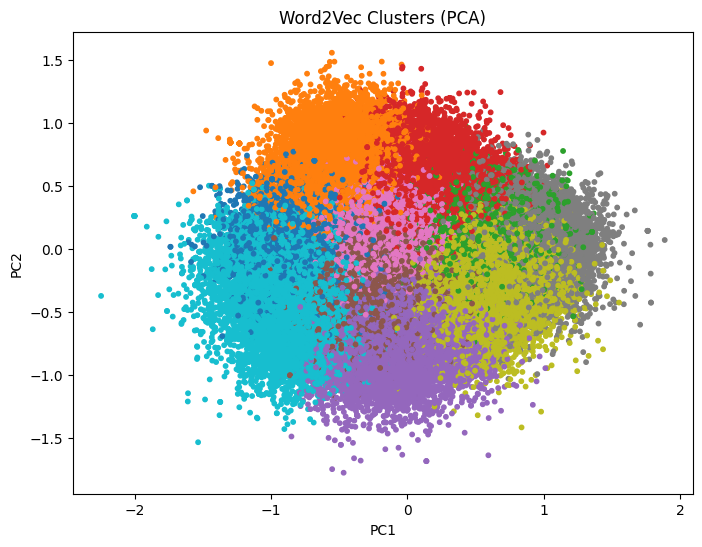

In [ ]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

pca = PCA(n_components=2)
X_w2v_pca = pca.fit_transform(X_w2v)

plt.figure(figsize=(8, 6))
plt.scatter(
    X_w2v_pca[:, 0],
    X_w2v_pca[:, 1],
    c=df['cluster_w2v'],
    s=10,
    cmap='tab10'
)

plt.title("Word2Vec Clusters (PCA)")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.show()


Both TF-IDF and Word2Vec can be used to cluster news headlines, but they behave very differently:

TF-IDF creates sparse, high-dimensional vectors based on word frequency, so PCA shows long, stretched patterns with less natural grouping. Clusters are harder to separate because TF-IDF lacks semantic understanding.

Word2Vec, on the other hand, produces dense semantic embeddings. Its PCA plot shows smoother, more compact distributions with clearer transitions between clusters. This happens because similar meanings get similar vectors.

Overall, Word2Vec captures semantic relationships much better and forms more coherent clusters than TF-IDF, making it the superior method for meaning-based tasks like topic clustering.